# Deep Learning Models for Electricity Demand Forecasting


**Data:** ELD (Electricity Load Diagrams) aggregate daily demand series + weather exogenous features  
**Split:** 80 % train / 10 % val / 10 % test (khoảng thời gian, cùng tỷ lệ phân bổ như các mô hình thống kê)  
**Models:** LSTM · Transformer  
**Metrics:** MAPE · RMSE · Log-Likelihood · AIC

## 1. Imports

In [1]:
import math
import time
from pathlib import Path
from typing import Literal, Sequence

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import (
    ReduceLROnPlateau, SequentialLR, LinearLR, CosineAnnealingLR,
)
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    'figure.figsize': (14, 4),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

## 2. Configuration

In [2]:
PARQUET_DIR    = '../../data'
DEMAND_PATH    = f'{PARQUET_DIR}/demand.parquet'
METADATA_PATH  = f'{PARQUET_DIR}/metadata.parquet'
WEATHER_PATH   = f'{PARQUET_DIR}/weather.parquet'

LOOKBACK    = 365    # dữ liệu lịch sử được dùng để dự đoán ngày hôm sau.
BATCH_SIZE  = 64
EPOCHS      = 100
PATIENCE    = 15

CKPT_LSTM        = 'checkpoints_lstm'
CKPT_TRANSFORMER = 'checkpoints_transformer'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


## 3. Data Pipeline

**`TimeSeriesDataset`** — Lớp bọc PyTorch `Dataset` cho các mảng cửa sổ trượt (sliding-window) đã dựng sẵn

**`build_sequences`** — Tạo các cặp `(X[i:i+seq_len], y[i+seq_len])` kèm metadata id/thời gian tương ứng

In [3]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X_seq, y_seq):
        self.X = torch.from_numpy(X_seq)
        self.y = torch.from_numpy(y_seq)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def build_sequences(X, y, ids, times, seq_len):
    """Sliding-window sequences: input X[i:i+seq_len], target y[i+seq_len]."""
    X_seq, y_out, ids_out, times_out = [], [], [], []
    for i in range(len(X) - seq_len):
        X_seq.append(X[i : i + seq_len])
        y_out.append(y[i + seq_len])
        ids_out.append(ids[i + seq_len])
        times_out.append(times[i + seq_len])
    if not X_seq:
        return (
            np.empty((0, seq_len, X.shape[1]), dtype=np.float32),
            np.empty((0, y.shape[1]), dtype=np.float32),
            np.array([]), np.array([]),
        )
    return (
        np.array(X_seq, dtype=np.float32),
        np.array(y_out,  dtype=np.float32),
        np.array(ids_out),
        np.array(times_out),
    )

## 4. ELD Aggregate Data Loader

Gộp các file parquet thô thành một chuỗi nhu cầu trung bình theo ngày, ghép với đặc trưng thời tiết, rồi xây dựng các `DataLoader` cho train / val / test bằng cửa sổ trượt (sliding windows).

**Đặc trưng đầu vào** (tổng cộng 9):  
- Thời tiết (cùng bộ biến với SARIMAX): `soil_temperature_7_to_28cm`, `soil_temperature_0_to_7cm`, `apparent_temperature`, `temperature_2m`  
- Tự hồi quy (autoregressive): nhu cầu trễ `y` (các giá trị mục tiêu trong quá khứ)  
- Thời gian (dạng lượng giác chu kỳ): `day_of_week_sin/cos`, `day_of_year_sin/cos`

In [5]:
DEFAULT_WEATHER_FEATURES = [
    'soil_temperature_7_to_28cm',
    'soil_temperature_0_to_7cm',
    'apparent_temperature',
    'temperature_2m',
]
SYNTHETIC_AGG_ID = 'ELD_AGG'


def _valid_fifteen_minute_labels():
    return [t.strftime('%H:%M') for t in pd.date_range('00:00', '23:45', freq='15min')]


def load_eldd_daily_aggregate(
    demand_path, metadata_path, weather_path,
    dataset_name='Electricity Load Diagrams',
    weather_feature_cols=None,
):
    """Daily-mean demand joined with daily-mean weather features."""
    demand_path   = str(Path(demand_path).resolve()).replace('\\', '/')
    metadata_path = str(Path(metadata_path).resolve()).replace('\\', '/')
    weather_path  = str(Path(weather_path).resolve()).replace('\\', '/')
    if weather_feature_cols is None:
        weather_feature_cols = list(DEFAULT_WEATHER_FEATURES)

    valid     = _valid_fifteen_minute_labels()
    valid_sql = ','.join(f"'{v}'" for v in valid)
    con = duckdb.connect()
    try:
        t0 = time.time()
        demand_daily = con.execute(f"""
            SELECT CAST(d.timestamp AS DATE) AS date,
                   AVG(d.y) AS y
            FROM read_parquet('{demand_path}') AS d
            INNER JOIN (
                SELECT unique_id FROM read_parquet('{metadata_path}')
                WHERE dataset = '{dataset_name}'
            ) AS m ON d.unique_id = m.unique_id
            WHERE strftime(d.timestamp, '%H:%M') IN ({valid_sql})
            GROUP BY 1 ORDER BY 1
        """).df()
        print(f'[ELD] Demand: {len(demand_daily)} rows in {time.time()-t0:.2f}s')

        cols_sql = ', '.join(f'AVG({c}) AS {c}' for c in weather_feature_cols)
        weather_daily = con.execute(f"""
            SELECT CAST(timestamp AS DATE) AS date, {cols_sql}
            FROM read_parquet('{weather_path}')
            GROUP BY 1 ORDER BY 1
        """).df()
        print(f'[ELD] Weather: {len(weather_daily)} rows')
    finally:
        con.close()

    demand_daily['date']  = pd.to_datetime(demand_daily['date'])
    weather_daily['date'] = pd.to_datetime(weather_daily['date'])
    merged = pd.merge(demand_daily, weather_daily, on='date', how='inner')
    merged = merged.sort_values('date').reset_index(drop=True).ffill().dropna()
    if merged.empty:
        raise ValueError('ELD merge produced no rows.')

    merged['day_of_week_sin'] = np.sin(2 * np.pi * merged['date'].dt.dayofweek / 7)
    merged['day_of_week_cos'] = np.cos(2 * np.pi * merged['date'].dt.dayofweek / 7)
    merged['day_of_year_sin'] = np.sin(2 * np.pi * merged['date'].dt.dayofyear / 365.25)
    merged['day_of_year_cos'] = np.cos(2 * np.pi * merged['date'].dt.dayofyear / 365.25)

    return merged


def get_dataloaders_eldd_aggregate(
    demand_parquet, metadata_parquet, weather_parquet,
    dataset_name='Electricity Load Diagrams',
    weather_feature_cols=None,
    lookback_length=7,
    batch_size=64,
    test_cutoff='2024-01-01',
    test_end='2025-01-01',
    target_col='y',
):
    """
    End-to-end: parquet -> scaled sliding-window DataLoaders.

    Split mirrors SARIMAX.ipynb:
      train : date <  test_cutoff
      val   : date >= test_cutoff (same samples as test)
      test  : test_cutoff <= date <= test_end

    The last `lookback_length` rows of the training set are prepended as
    context when building test sequences, so every day in
    [test_cutoff, test_end] has a full lookback window available.
    """
    if weather_feature_cols is None:
        weather_feature_cols = list(DEFAULT_WEATHER_FEATURES)

    df = load_eldd_daily_aggregate(
        demand_parquet, metadata_parquet, weather_parquet,
        dataset_name=dataset_name, weather_feature_cols=weather_feature_cols,
    )
    temporal_cols = [
        'day_of_week_sin', 'day_of_week_cos',
        'day_of_year_sin', 'day_of_year_cos',
    ]
    feature_cols = list(weather_feature_cols) + [target_col] + temporal_cols
    seq_len      = lookback_length
    cutoff       = pd.Timestamp(test_cutoff)
    end          = pd.Timestamp(test_end)

    df_train = df[df['date'] <  cutoff].reset_index(drop=True)
    df_test  = df[(df['date'] >= cutoff) & (df['date'] <= end)].reset_index(drop=True)

    if len(df_train) < seq_len:
        raise ValueError(f'train split has only {len(df_train)} rows (need >= {seq_len})')
    if len(df_test) == 0:
        raise ValueError('test split is empty — check test_cutoff / test_end range')

    # Fit scalers on training data only
    scaler_X = StandardScaler().fit(df_train[feature_cols].values.astype(np.float64))
    scaler_y = StandardScaler().fit(df_train[[target_col]].values.astype(np.float64))

    def _make_loader(df_split, shuffle):
        X = scaler_X.transform(df_split[feature_cols].values.astype(np.float64)).astype(np.float32)
        y = scaler_y.transform(df_split[[target_col]].values.astype(np.float64)).astype(np.float32)
        ids   = np.full(len(df_split), SYNTHETIC_AGG_ID, dtype=object)
        times = df_split['date'].values
        X_seq, y_seq, id_seq, time_seq = build_sequences(X, y, ids, times, seq_len)
        ds = TimeSeriesDataset(X_seq, y_seq)
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, pin_memory=True), id_seq, time_seq

    def _make_test_loader(df_context, df_split):
        # Prepend the last seq_len training rows so the first test day
        # (test_cutoff) has a full lookback window without needing warm-up.
        df_combined = pd.concat([df_context.tail(seq_len), df_split], ignore_index=True)
        X = scaler_X.transform(df_combined[feature_cols].values.astype(np.float64)).astype(np.float32)
        y = scaler_y.transform(df_combined[[target_col]].values.astype(np.float64)).astype(np.float32)
        ids   = np.full(len(df_combined), SYNTHETIC_AGG_ID, dtype=object)
        times = df_combined['date'].values
        X_seq, y_seq, id_seq, time_seq = build_sequences(X, y, ids, times, seq_len)
        # Sequences whose target falls inside the test window only
        test_mask = np.array([pd.Timestamp(t) >= cutoff for t in time_seq])
        X_seq, y_seq = X_seq[test_mask], y_seq[test_mask]
        id_seq, time_seq = id_seq[test_mask], time_seq[test_mask]
        ds = TimeSeriesDataset(X_seq, y_seq)
        loader = DataLoader(ds, batch_size=batch_size, shuffle=False, pin_memory=True)
        return loader, id_seq, time_seq

    train_loader, _, _                 = _make_loader(df_train, shuffle=True)
    test_loader,  test_ids, test_times = _make_test_loader(df_train, df_test)
    val_loader = test_loader  # validate on test samples during training

    print(f'[ELD] train sequences : {len(train_loader.dataset)}')
    print(f'[ELD] val/test sequences : {len(test_loader.dataset)} '
          f'({test_cutoff} .. {test_end})')
    print(f'[ELD] train {df_train["date"].min().date()} .. {df_train["date"].max().date()}')
    print(f'[ELD] test  {pd.Timestamp(test_times[0]).date()} .. {pd.Timestamp(test_times[-1]).date()}')

    metadata = {
        'scaler_X': scaler_X, 'scaler_y': scaler_y,
        'feature_cols': feature_cols, 'target_col': target_col,
        'seq_len': seq_len, 'forecast_unit': 'day',
        'lookback_length': lookback_length,
        'test_ids': test_ids, 'test_times': test_times,
    }
    return train_loader, val_loader, test_loader, metadata

## 5. Model Architectures

### LSTM

### Transformer


In [6]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=2, dropout=0.2):
        super().__init__()
        self.num_layers  = num_layers
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, 1),
        )

    def forward(self, x):
        out, _ = self.lstm(x)         # (batch, seq_len, hidden)
        return self.head(out[:, -1])  # last time-step -> scalar


def _sinusoidal_encoding(seq_len, d_model, device):
    pe  = torch.zeros(seq_len, d_model, device=device)
    pos = torch.arange(seq_len, dtype=torch.float, device=device).unsqueeze(1)
    div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float, device=device)
                    * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe


class TransformerForecastModel(nn.Module):
    def __init__(
        self, input_size, d_model=64, nhead=4,
        num_encoder_layers=2, dim_feedforward=128,
        dropout=0.3, max_seq_len=64,
        pool_mode: Literal['last', 'mean', 'attention'] = 'attention',
    ):
        super().__init__()
        self.d_model      = d_model
        self._max_seq_len = max_seq_len
        self.pool_mode    = pool_mode
        self.input_proj   = nn.Linear(input_size, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True,
        )
        self.encoder    = nn.TransformerEncoder(enc_layer, num_layers=num_encoder_layers)
        self.pool_attn  = nn.Linear(d_model, 1) if pool_mode == 'attention' else None
        self.out_norm   = nn.LayerNorm(d_model)
        self.fc_out     = nn.Linear(d_model, 1)

    def _pool(self, h):
        if self.pool_mode == 'last':
            return h[:, -1]
        if self.pool_mode == 'mean':
            return h.mean(dim=1)
        w = torch.softmax(self.pool_attn(h), dim=1)
        return (h * w).sum(dim=1)

    def forward(self, x):
        _, seq_len, _ = x.shape
        x  = self.input_proj(x)
        pe = _sinusoidal_encoding(max(seq_len, self._max_seq_len), self.d_model, x.device)
        x  = x + pe[:seq_len].unsqueeze(0)
        return self.fc_out(self.out_norm(self._pool(self.encoder(x))))

## 6. Training

**`train_model`** runs the training loop with validation, early stopping, and checkpoint saving.  
**`evaluate`** runs inference and inverse-transforms predictions back to the original demand scale.

In [7]:
def _save_ckpt(path, model, optimizer, epoch, history, metadata):
    model_type = 'lstm' if isinstance(model, LSTMModel) else 'transformer'
    d = {
        'model_state_dict':    model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'epoch': epoch + 1, 'history': history,
        'scaler_y_mean':  metadata['scaler_y'].mean_.tolist(),
        'scaler_y_scale': metadata['scaler_y'].scale_.tolist(),
        'model_type': model_type,
        'seq_len': metadata['seq_len'],
        'feature_cols': metadata['feature_cols'],
    }
    torch.save(d, path)


def regression_metrics(preds, targets, eps=1e-8):
    preds, targets = np.asarray(preds).ravel(), np.asarray(targets).ravel()
    err  = preds - targets
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae  = float(np.mean(np.abs(err)))
    mape = float(np.mean(np.abs(err) / np.maximum(np.abs(targets), eps)))
    return {'rmse': rmse, 'mae': mae, 'mape': mape}


def train_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler,
    device, epochs=100, patience=15, checkpoint_dir='checkpoints',
    data_metadata=None, grad_clip_max_norm=None,
):
    """Training loop with early stopping; saves best.pt / last.pt checkpoints."""
    ckpt_dir = Path(checkpoint_dir)
    ckpt_dir.mkdir(parents=True, exist_ok=True)

    history = {'train_loss': [], 'val_loss': []}
    best_val, no_improve = float('inf'), 0

    for epoch in range(epochs):
        # --- train ---
        model.train()
        train_losses = []
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            if grad_clip_max_norm:
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip_max_norm)
            optimizer.step()
            train_losses.append(loss.item())
        mean_train = float(np.mean(train_losses))
        history['train_loss'].append(mean_train)

        # --- validate ---
        model.eval()
        val_losses = []
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                val_losses.append(criterion(model(Xb), yb).item())
        mean_val = float(np.mean(val_losses))
        history['val_loss'].append(mean_val)

        # --- scheduler ---
        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(mean_val)
            else:
                scheduler.step()

        print(f'Epoch {epoch+1:>3}/{epochs}  train={mean_train:.6f}  val={mean_val:.6f}')

        # --- checkpointing & early stopping ---
        if mean_val < best_val:
            best_val, no_improve = mean_val, 0
            if data_metadata:
                _save_ckpt(ckpt_dir / 'best.pt', model, optimizer, epoch, history, data_metadata)
                print(f'  [best] saved  val={mean_val:.6f}')
        else:
            no_improve += 1
        if data_metadata:
            _save_ckpt(ckpt_dir / 'last.pt', model, optimizer, epoch, history, data_metadata)
        if no_improve >= patience:
            print(f'Early stopping at epoch {epoch+1}')
            break

    return history


def evaluate(model, loader, scaler_y, device, ids=None, times=None):
    """Run inference; return (rmse, mae, mape, preds_orig, targets_orig, results_df)."""
    model.eval()
    preds_list, targets_list = [], []
    with torch.no_grad():
        for Xb, yb in loader:
            preds_list.append(model(Xb.to(device)).cpu().numpy())
            targets_list.append(yb.numpy())
    preds   = np.concatenate(preds_list)
    targets = np.concatenate(targets_list)
    preds_orig   = scaler_y.inverse_transform(preds)
    targets_orig = scaler_y.inverse_transform(targets)
    m = regression_metrics(preds_orig, targets_orig)
    results_df = None
    if ids is not None and times is not None:
        results_df = pd.DataFrame({
            'unique_id': ids.ravel(),
            'timestamp': pd.to_datetime(times.ravel()),
            'Actual':    targets_orig.ravel(),
            'Predicted': preds_orig.ravel(),
        }).sort_values(['unique_id', 'timestamp']).reset_index(drop=True)
    return m['rmse'], m['mae'], m['mape'], preds_orig, targets_orig, results_df

## 7. Evaluation & Plot Helpers

Log-likelihood and AIC use a Gaussian MLE approximation — consistent with the statsmodels `.llf` / `.aic` reported by ARIMA/SARIMAX/GP models in the statistical notebook:

$$\ell = -\frac{n}{2}\!\left(\ln 2\pi + \ln\hat\sigma^2 + 1\right), \quad\hat\sigma^2 = \frac{\mathrm{RSS}}{n}, \quad \mathrm{AIC} = 2k - 2\ell$$

In [8]:
def gaussian_log_likelihood(residuals):
    n      = len(residuals)
    sigma2 = float(np.sum(residuals ** 2)) / n
    return -n / 2 * (np.log(2 * np.pi) + np.log(sigma2) + 1)


def eval_model(model, loader, scaler_y, device, ids=None, times=None):
    """Evaluate and return metrics dict + results DataFrame."""
    rmse, mae, mape, preds, targets, results_df = evaluate(
        model, loader, scaler_y, device, ids, times
    )
    residuals = targets.ravel() - preds.ravel()
    ll  = gaussian_log_likelihood(residuals)
    k   = sum(p.numel() for p in model.parameters())
    aic = 2 * k - 2 * ll
    return {'MAPE': mape, 'RMSE': rmse, 'Log-Likelihood': ll, 'AIC': aic}, results_df


def print_metrics(name, metrics):
    print(f'{name} — Test Results')
    print(f"  MAPE            : {metrics['MAPE']:.4f}  ({metrics['MAPE']*100:.2f}%)")
    print(f"  RMSE            : {metrics['RMSE']:.4f}")
    print(f"  Log-Likelihood  : {metrics['Log-Likelihood']:.4f}")
    print(f"  AIC             : {metrics['AIC']:.4f}")

In [9]:
def plot_loss(history, title='Training History', ax=None):
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(10, 4))
    epochs = range(1, len(history['train_loss']) + 1)
    ax.plot(epochs, history['train_loss'], label='Train', linewidth=1.5)
    ax.plot(epochs, history['val_loss'],   label='Val',   linewidth=1.5, linestyle='--')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss (scaled)'); ax.set_title(title); ax.legend()
    if own: plt.tight_layout(); plt.show()


def plot_forecast(results_df, title='Forecast vs Actual', ax=None):
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(results_df['timestamp'], results_df['Actual'],    label='Actual',    linewidth=1.5)
    ax.plot(results_df['timestamp'], results_df['Predicted'], label='Predicted', linewidth=1.5, alpha=0.85)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    ax.set_xlabel('Date'); ax.set_ylabel('Mean Daily Demand'); ax.set_title(title); ax.legend()
    if own: plt.tight_layout(); plt.show()

## 8. Load Data

In [10]:
train_loader, val_loader, test_loader, metadata = get_dataloaders_eldd_aggregate(
    demand_parquet   = DEMAND_PATH,
    metadata_parquet = METADATA_PATH,
    weather_parquet  = WEATHER_PATH,
    lookback_length  = LOOKBACK,
    batch_size       = BATCH_SIZE,
    test_cutoff      = '2024-01-01',
    test_end         = '2025-01-01',
)

feature_cols = metadata['feature_cols']
scaler_y     = metadata['scaler_y']
test_ids     = metadata['test_ids']
test_times   = metadata['test_times']
input_size   = len(feature_cols)

print(f'\nFeatures ({input_size}): {feature_cols}')
print(f'Batches — train: {len(train_loader)}  val/test: {len(test_loader)}')

[ELD] Demand: 1461 rows in 4.39s
[ELD] Weather: 1825 rows
[ELD] train sequences : 730
[ELD] val/test sequences : 366 (2024-01-01 .. 2025-01-01)
[ELD] train 2021-01-01 .. 2023-12-31
[ELD] test  2024-01-01 .. 2025-01-01

Features (9): ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m', 'y', 'day_of_week_sin', 'day_of_week_cos', 'day_of_year_sin', 'day_of_year_cos']
Batches — train: 12  val/test: 6


---
## 9. LSTM

Two-layer LSTM, hidden size 128, MLP head, dropout 0.2.  
**Optimizer:** AdamW lr=1e-3, wd=1e-4 · **Scheduler:** 5-epoch linear warmup → CosineAnnealingLR · **Loss:** HuberLoss(δ=1.0)

In [11]:
lstm = LSTMModel(input_size=input_size, hidden_size=128, num_layers=2, dropout=0.2).to(DEVICE)
print(f'LSTM parameters: {sum(p.numel() for p in lstm.parameters()):,}')

criterion  = nn.HuberLoss(delta=1.0)
lstm_opt   = torch.optim.AdamW(lstm.parameters(), lr=1e-3, weight_decay=1e-4)
LSTM_WARMUP = 5
lstm_sched = SequentialLR(
    lstm_opt,
    schedulers=[
        LinearLR(lstm_opt, start_factor=0.1, end_factor=1.0, total_iters=LSTM_WARMUP),
        CosineAnnealingLR(lstm_opt, T_max=EPOCHS - LSTM_WARMUP, eta_min=1e-6),
    ],
    milestones=[LSTM_WARMUP],
)

LSTM parameters: 211,585


### 9.1 Train

In [12]:
lstm_history = train_model(
    lstm, train_loader, val_loader, criterion,
    lstm_opt, lstm_sched, DEVICE,
    epochs=EPOCHS, patience=PATIENCE,
    checkpoint_dir=CKPT_LSTM, data_metadata=metadata,
)

C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch   1/100  train=0.465576  val=0.492731
  [best] saved  val=0.492731
Epoch   2/100  train=0.437282  val=0.436009
  [best] saved  val=0.436009
Epoch   3/100  train=0.274809  val=0.097679
  [best] saved  val=0.097679
Epoch   4/100  train=0.102155  val=0.090543
  [best] saved  val=0.090543
Epoch   5/100  train=0.074594  val=0.092996
Epoch   6/100  train=0.068113  val=0.078488
  [best] saved  val=0.078488
Epoch   7/100  train=0.064350  val=0.079311
Epoch   8/100  train=0.064438  val=0.079062
Epoch   9/100  train=0.060753  val=0.074801
  [best] saved  val=0.074801
Epoch  10/100  train=0.055909  val=0.056873
  [best] saved  val=0.056873
Epoch  11/100  train=0.049353  val=0.058147
Epoch  12/100  train=0.048519  val=0.059448
Epoch  13/100  train=0.049076  val=0.058753
Epoch  14/100  train=0.042381  val=0.039241
  [best] saved  val=0.039241
Epoch  15/100  train=0.041886  val=0.041314
Epoch  16/100  train=0.037550  val=0.032618
  [best] saved  val=0.032618
Epoch  17/100  train=0.035117  val=

### 9.2 Training Curve

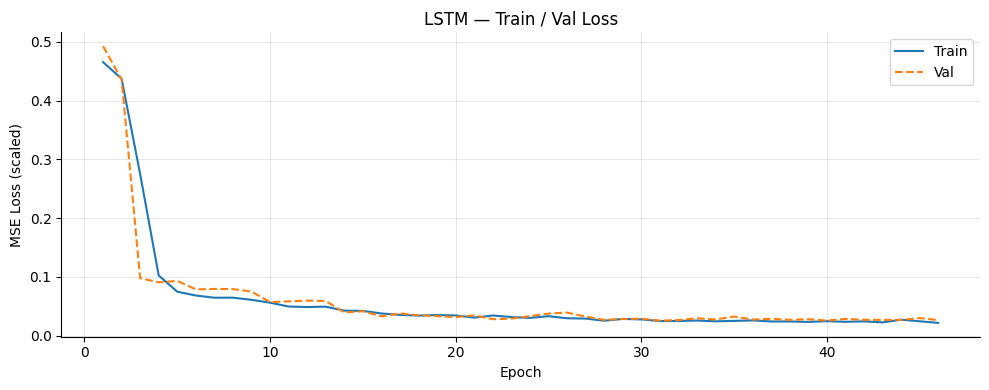

In [13]:
plot_loss(lstm_history, title='LSTM — Train / Val Loss')

### 9.3 Test Evaluation

In [14]:
lstm_metrics, lstm_results = eval_model(
    lstm, test_loader, scaler_y, DEVICE, ids=test_ids, times=test_times
)
print_metrics('LSTM', lstm_metrics)

LSTM — Test Results
  MAPE            : 0.0290  (2.90%)
  RMSE            : 6.7067
  Log-Likelihood  : -1215.8690
  AIC             : 425601.7380


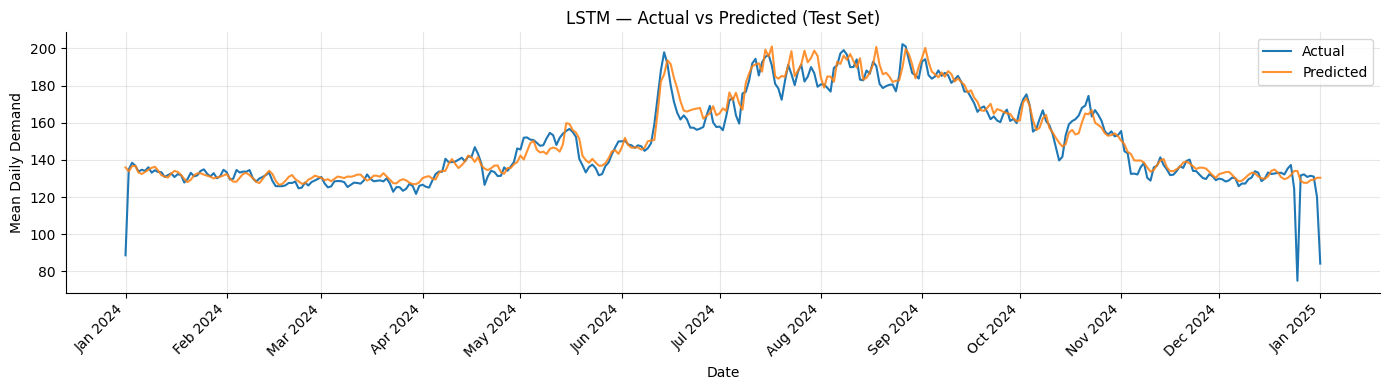

In [15]:
plot_forecast(lstm_results, title='LSTM — Actual vs Predicted (Test Set)')

---
## 10. Transformer

2-layer pre-norm Transformer encoder, 4 heads, d_model=64, ff=128, dropout=0.3, attention pooling, LayerNorm output.  
**Optimizer:** AdamW lr=4e-4, wd=1e-3 · **Scheduler:** 5-epoch linear warmup → CosineAnnealingLR · **Loss:** HuberLoss(δ=1.0) · **Grad clip:** 1.0

In [16]:
WARMUP = 5

transformer = TransformerForecastModel(
    input_size=input_size, d_model=64, nhead=4,
    num_encoder_layers=2, dim_feedforward=128,
    dropout=0.3, max_seq_len=LOOKBACK, pool_mode='attention',
).to(DEVICE)
print(f'Transformer parameters: {sum(p.numel() for p in transformer.parameters()):,}')

tr_opt   = torch.optim.AdamW(transformer.parameters(), lr=4e-4, weight_decay=1e-3)
tr_sched = SequentialLR(
    tr_opt,
    schedulers=[
        LinearLR(tr_opt, start_factor=0.1, end_factor=1.0, total_iters=WARMUP),
        CosineAnnealingLR(tr_opt, T_max=EPOCHS - WARMUP, eta_min=1e-6),
    ],
    milestones=[WARMUP],
)

Transformer parameters: 67,842


C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\nn\modules\transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


### 10.1 Train

In [17]:
transformer_history = train_model(
    transformer, train_loader, val_loader, criterion,
    tr_opt, tr_sched, DEVICE,
    epochs=EPOCHS, patience=PATIENCE,
    checkpoint_dir=CKPT_TRANSFORMER, data_metadata=metadata,
    grad_clip_max_norm=1.0,
)

C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch   1/100  train=0.374350  val=0.280657
  [best] saved  val=0.280657
Epoch   2/100  train=0.332498  val=0.231990
  [best] saved  val=0.231990
Epoch   3/100  train=0.249295  val=0.119393
  [best] saved  val=0.119393
Epoch   4/100  train=0.134344  val=0.095851
  [best] saved  val=0.095851
Epoch   5/100  train=0.084671  val=0.054609
  [best] saved  val=0.054609
Epoch   6/100  train=0.059297  val=0.066860
Epoch   7/100  train=0.057917  val=0.064199
Epoch   8/100  train=0.054717  val=0.073863
Epoch   9/100  train=0.055582  val=0.063047
Epoch  10/100  train=0.050033  val=0.075861
Epoch  11/100  train=0.049965  val=0.066484
Epoch  12/100  train=0.048214  val=0.065814
Epoch  13/100  train=0.049180  val=0.064157
Epoch  14/100  train=0.050271  val=0.066853
Epoch  15/100  train=0.046794  val=0.070570
Epoch  16/100  train=0.048464  val=0.066624
Epoch  17/100  train=0.049547  val=0.063972
Epoch  18/100  train=0.046667  val=0.071447
Epoch  19/100  train=0.053999  val=0.074200
Epoch  20/100  trai

### 10.2 Training Curve

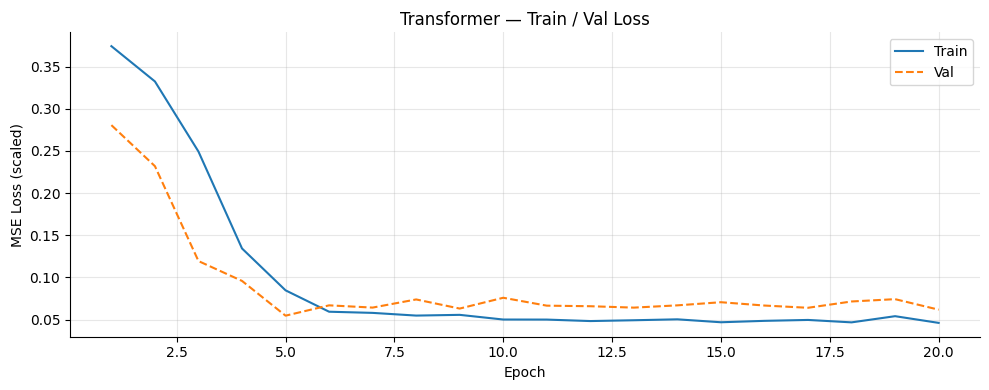

In [18]:
plot_loss(transformer_history, title='Transformer — Train / Val Loss')

### 10.3 Test Evaluation

In [19]:
transformer_metrics, transformer_results = eval_model(
    transformer, test_loader, scaler_y, DEVICE, ids=test_ids, times=test_times
)
print_metrics('Transformer', transformer_metrics)

Transformer — Test Results
  MAPE            : 0.0473  (4.73%)
  RMSE            : 10.3382
  Log-Likelihood  : -1374.2507
  AIC             : 138432.5014


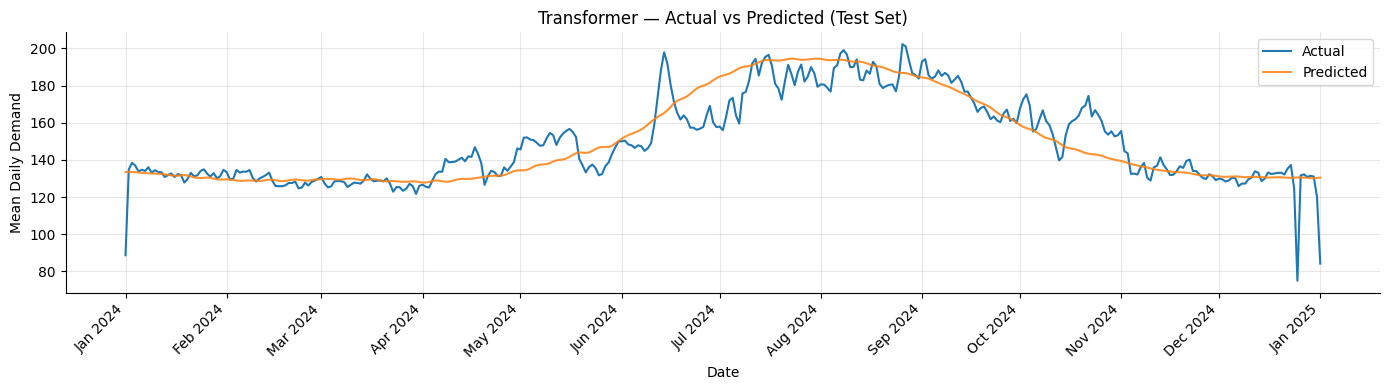

In [20]:
plot_forecast(transformer_results, title='Transformer — Actual vs Predicted (Test Set)')

In [21]:
transformer_results

,unique_id,timestamp,Actual,Predicted
0,ELD_AGG,2024-01-01,88.664688,133.419159
1,ELD_AGG,2024-01-02,134.861298,133.565048
2,ELD_AGG,2024-01-03,138.458298,133.532852
3,ELD_AGG,2024-01-04,136.896027,133.354004
4,ELD_AGG,2024-01-05,133.716858,133.157288
...,...,...,...,...
361,ELD_AGG,2024-12-28,130.841873,130.352036
362,ELD_AGG,2024-12-29,131.448593,130.188217
363,ELD_AGG,2024-12-30,131.036743,130.147537
364,ELD_AGG,2024-12-31,120.008003,130.290192


---
## 11. Side-by-Side Comparison

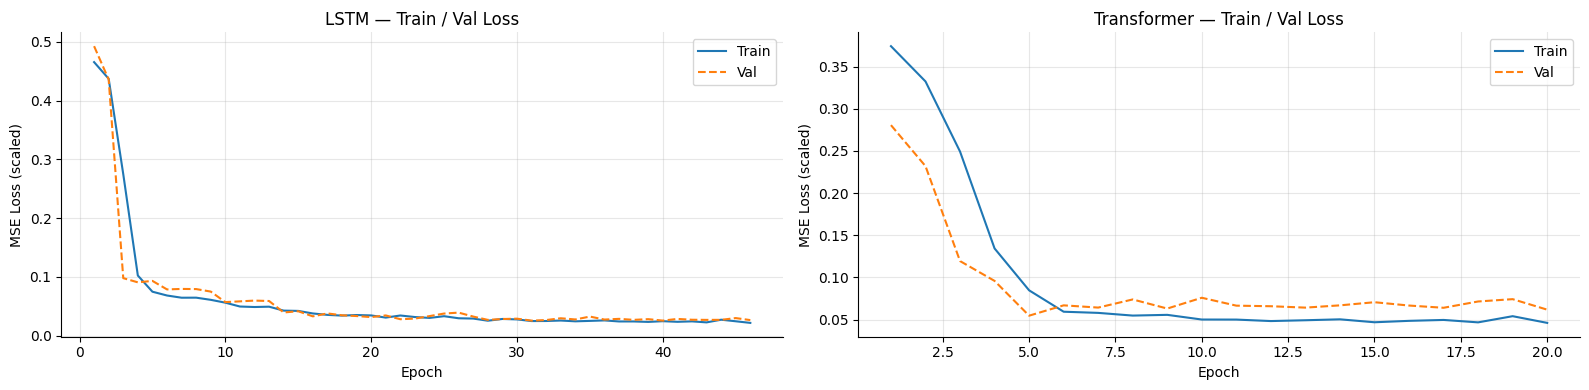

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_loss(lstm_history,        title='LSTM — Train / Val Loss',        ax=axes[0])
plot_loss(transformer_history, title='Transformer — Train / Val Loss', ax=axes[1])
plt.tight_layout(); plt.show()

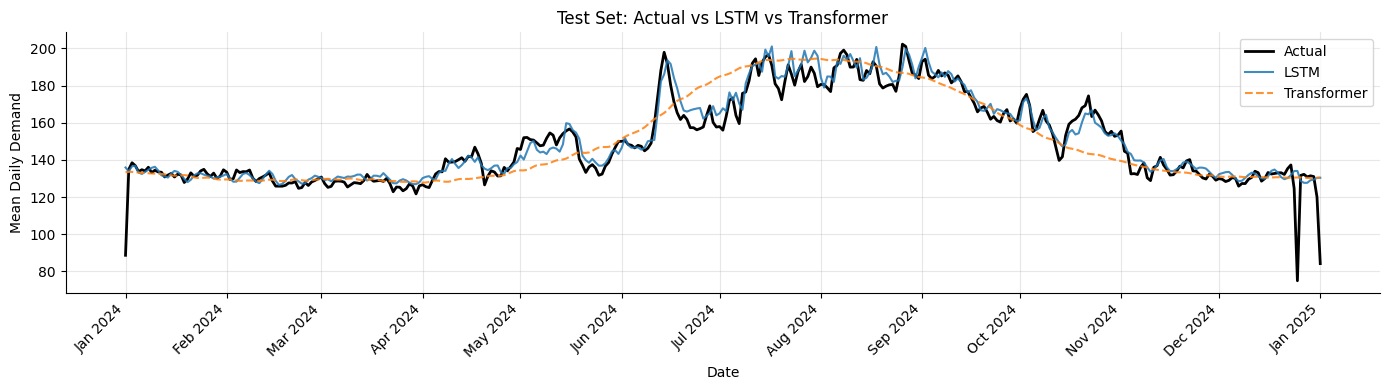

In [23]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(lstm_results['timestamp'],        lstm_results['Actual'],           label='Actual',      lw=2, color='black')
ax.plot(lstm_results['timestamp'],        lstm_results['Predicted'],        label='LSTM',        lw=1.5, alpha=0.85)
ax.plot(transformer_results['timestamp'], transformer_results['Predicted'], label='Transformer', lw=1.5, alpha=0.85, ls='--')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
ax.set_xlabel('Date'); ax.set_ylabel('Mean Daily Demand')
ax.set_title('Test Set: Actual vs LSTM vs Transformer'); ax.legend()
plt.tight_layout(); plt.show()

---
## 12. Results Summary

Metrics on the held-out test set, reported in the same format as the statistical models.

In [24]:
summary = pd.DataFrame([
    {'Model': 'LSTM',        **lstm_metrics},
    {'Model': 'Transformer', **transformer_metrics},
]).set_index('Model')

fmt = summary.copy()
fmt['MAPE']           = fmt['MAPE'].map('{:.2%}'.format)
fmt['RMSE']           = fmt['RMSE'].map('{:.4f}'.format)
fmt['Log-Likelihood'] = fmt['Log-Likelihood'].map('{:.2f}'.format)
fmt['AIC']            = fmt['AIC'].map('{:.2f}'.format)
display(fmt)

,MAPE,RMSE,Log-Likelihood,AIC
Model,,,,
LSTM,2.90%,6.7067,-1215.87,425601.74
Transformer,4.73%,10.3382,-1374.25,138432.50


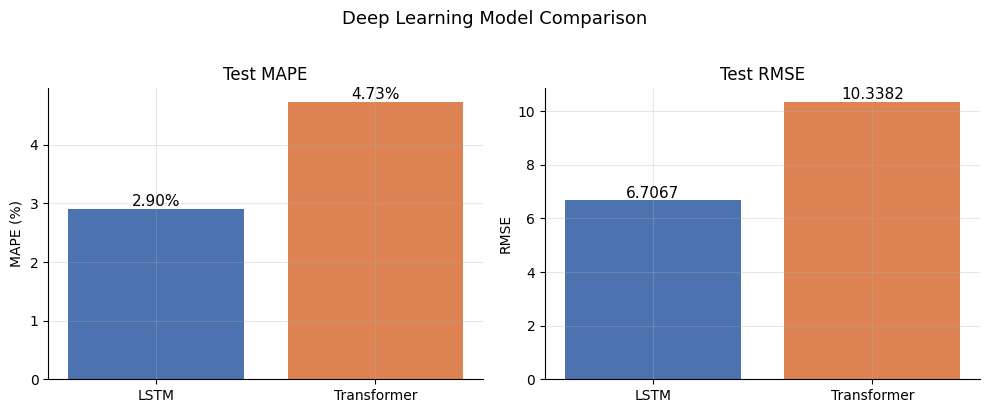

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
models = summary.index.tolist()
colors = ['#4C72B0', '#DD8452']

axes[0].bar(models, summary['MAPE'] * 100, color=colors)
axes[0].set_ylabel('MAPE (%)'); axes[0].set_title('Test MAPE')
for i, v in enumerate(summary['MAPE'] * 100):
    axes[0].text(i, v + 0.05, f'{v:.2f}%', ha='center', fontsize=11)

axes[1].bar(models, summary['RMSE'], color=colors)
axes[1].set_ylabel('RMSE'); axes[1].set_title('Test RMSE')
for i, v in enumerate(summary['RMSE']):
    axes[1].text(i, v * 1.01, f'{v:.4f}', ha='center', fontsize=11)

plt.suptitle('Deep Learning Model Comparison', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()